# HW1

**Weeks 1–3**

Overview of the homework:

1. Write a forward Euler solver and check it against a known solution.
2. Construct two greenhouse models with the same surface temperature and compare their energy budgets.
3. Investigate what controls the amount and pace of warming, and distinguish temperature change from heat storage.

Use NumPy and Matplotlib. Cells marked **TODO** need your code; written responses go in the answer cells. Calls to unfinished functions will raise a `NotImplementedError` until you replace the indicated lines with your implementation. Most plotting code is supplied so you can concentrate on the calculations. In 3d and 3e, adapt earlier plotting examples to make your own comparisons. Feel free to add more plots if you feel the need. Using AI to help with plotting is fair game, but avoid using AI to solve the computing/modeling aspects (except to debug code). 

Try to guess what will happen before running cells. Make sure to label quantities with units and explain results in your own words. You may refer to the course slides and labs if needed, but all the equations needed here are included below.

**Grading: 100 points total.**

| Part | Points |
|:--|--:|
| 1. Euler’s method and numerical error | 25 |
| 2. Greenhouse models and energy budgets | 35 |
| 3. Warming and energy storage | 40 |

A few sentences per written question are sufficient unless otherwise stated. Show the main steps in your algebra and include units with numerical results. Your initial guesses are assessed for the reasoning you give, not whether they turn out to be correct. Keep your original guess and explain any change in your understanding after the calculation. Partial credit is available for correct reasoning and intermediate steps.

**Submission:** save the completed notebook with its outputs in your private course repository and submit its link through Courseworks. The deadline will be specified with the assignment on Courseworks.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({'figure.figsize': (8, 4.5), 'font.size': 11})


## 1. Write your own Euler method

To understand how the Euler time-stepping method works, let's start with a problem whose answer we already know:

$$
\frac{dy}{dt}=\cos t,\qquad y(0)=0.
$$

Here t and y are dimensionless, and trigonometric arguments are in radians. In this case we know the exact solution is y(t) = sin(t), through analytical integration. We will use it to check our numerical calculation, not to compute the numerical updates.

Forward Euler (or just Euler) uses the slope at the **current** time and state to take a small step:

$$
y_{n+1}=y_n+\Delta t\left(\frac{dy}{dt}\right)_n.
$$

Here **n** counts the time steps, starting at n = 0. **yₙ** is the calculated value at the current time tₙ, and **yₙ₊₁** is the value at the next time. **Δt** is the time between successive steps (called `dt` in the code). The slope in the update is evaluated at the current time tₙ.


### 1a. Implement the loop

Complete `euler_cosine`. The time grid is supplied. Your function should:

- Allocate an array for y with the same length as `time`.
- Set its first value to zero.
- Use a `for` loop to calculate each next value from the current value and slope.
- Return the time and solution arrays.

`nsteps` is the number of updates; there are `nsteps + 1` saved states, including the initial state. Helpful tools are `np.zeros`, `len`, `range`, and `np.cos`.

**Do not use `np.sin` inside your solver.** Use it only outside the solver to check your results.


In [2]:
def euler_cosine(nsteps, t_end=2 * np.pi):
    """Integrate dy/dt = cos(t), starting from y(0) = 0."""
    time = np.linspace(0.0, t_end, nsteps + 1)
    dt = time[1] - time[0]
    # TODO: allocate y, set its initial value, and write the Euler loop.
    # Replace the next line with your implementation and return time, y.

    y = np.zeros(len(time))
    y[0] = 0.0

    for n in range(nsteps):
        dydt = np.cos(time[n])
        y[n + 1] = y[n] + dt * dydt
    return time, y


In [3]:
# Run your function and compare its first two steps with the exact solution.
time_short, y_short = euler_cosine(nsteps=2, t_end=1.0)
for t, value in zip(time_short, y_short):
    print(f't = {t:.1f}, numerical y = {value:.6f}, exact y = {np.sin(t):.6f}')


t = 0.0, numerical y = 0.000000, exact y = 0.000000
t = 0.5, numerical y = 0.500000, exact y = 0.479426
t = 1.0, numerical y = 0.938791, exact y = 0.841471


### 1b. Compare your calculation with the exact solution

Run your Euler function with **20 steps** from t = 0 to t = 2π. The code below plots your calculated values alongside the exact solution, sin(t).

Look at the two curves: do they lie on top of each other throughout the interval, or do you see a difference?


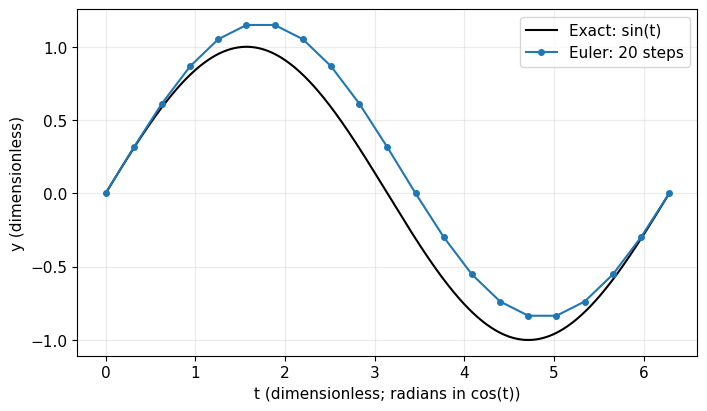

In [4]:
# Compare one numerical calculation with the exact solution.
time, y = euler_cosine(nsteps=20)
dense_time = np.linspace(0, 2 * np.pi, 500)
fig, ax = plt.subplots()
ax.plot(dense_time, np.sin(dense_time), color='black', label='Exact: sin(t)')
ax.plot(time, y, 'o-', label='Euler: 20 steps', markersize=4)
ax.set(xlabel='t (dimensionless; radians in cos(t))', ylabel='y (dimensionless)')
ax.grid(alpha=0.25)
ax.legend()
plt.show()


The difference between the numerical value and the exact value at the same time is called the **numerical error**:

$$
\text{error at }t_n = y_n - \sin(t_n).
$$

A positive error means your calculated value is above the exact value; a negative error means it is below. This difference can occur even when your code correctly implements Euler's method, because the method approximates the solution over each finite time step.

1. Describe where the two curves agree and where they differ most. Does agreement at the end mean the calculation was accurate throughout?
2. Euler uses the slope at the start of each step for the whole step. Explain why this can produce a difference from the exact solution when the slope changes during the step.


**Your response:**

At t = 0 , both are zero.

The curves separate most where the slope changes significantly.

With 20 steps, the largest error occurs near  t=π, . At that point the exact value is sin(π)=0, but Euler has accumulated positive error.

At the final time t=2π, both can look close again. In this special problem the final error is zero because the positive and negative slope contributions cancel in the Euler sum. That does not mean the calculation was accurate throughout.

Why Euler differs: Euler uses the slope at the start of the step for the whole step. If cost decreases during the step, Euler overestimates the slope and the calculated value is too high. If cost increases, it can underestimate. These errors accumulate.

### 1c. How does the time step affect the error?

Now that you have seen a difference between the calculated and exact curves, investigate whether smaller time steps reduce it. **Before running**, guess what will happen when Δt is halved, and briefly explain your reasoning.

Keep the same interval from t = 0 to t = 2π and use **20, 40, and 80 steps**. Since Δt is the interval length divided by the number of steps, doubling the number of steps halves Δt.

The supplied code plots both the solutions and their errors. To summarize each run, it also finds the **maximum absolute error**: the largest distance between a calculated value and the exact value at the saved times. Taking the absolute value counts differences on either side of the exact curve as positive distances.

$$
\text{maximum absolute error}=\max_n|y_n-\sin(t_n)|.
$$

1. Report Δt and the maximum absolute error for each run. Do the results support your guess?

2. Compare the error for 20 steps with that for 40 steps, and then 40 with 80. By approximately what factor does the maximum absolute error change each time Δt is halved?
3. What is the computational cost of taking smaller steps while keeping the duration fixed?


**Your guess and responses:**

1.
 20 steps: dt = 0.31416, max error = 0.314159, final error = 7.840e-17
 40 steps: dt = 0.15708, max error = 0.157080, final error = 1.894e-16
 80 steps: dt = 0.07854, max error = 0.078540, final error = 7.840e-17

Yes, the results support the guess. Halving Δt approximately halved the maximum absolute error. The final errors are essentially zero, but that is due to cancellation over the full interval; it does not mean the calculation was accurate throughout.

2.
20 steps to 40 steps: 0.314159/0.157080 ≈ 2.00
40 steps to 80 steps: 0.157080/0.078540 ≈ 2.00

So each time Δtis halved, the maximum absolute error decreases by a factor of about 2. This is the expected first-order behavior of forward Euler.

3.

Keeping the total time interval fixed, halving Δt doubles the number of time steps. Therefore the computational cost roughly doubles each time Δt is halved. We get better accuracy, but need to do about twice as many slope evaluations and updates.

 20 steps: dt = 0.31416, max error = 0.314159, final error = 7.840e-17
 40 steps: dt = 0.15708, max error = 0.157080, final error = 1.894e-16
 80 steps: dt = 0.07854, max error = 0.078540, final error = 7.840e-17
Successive maximum-error ratios: [2. 2.]


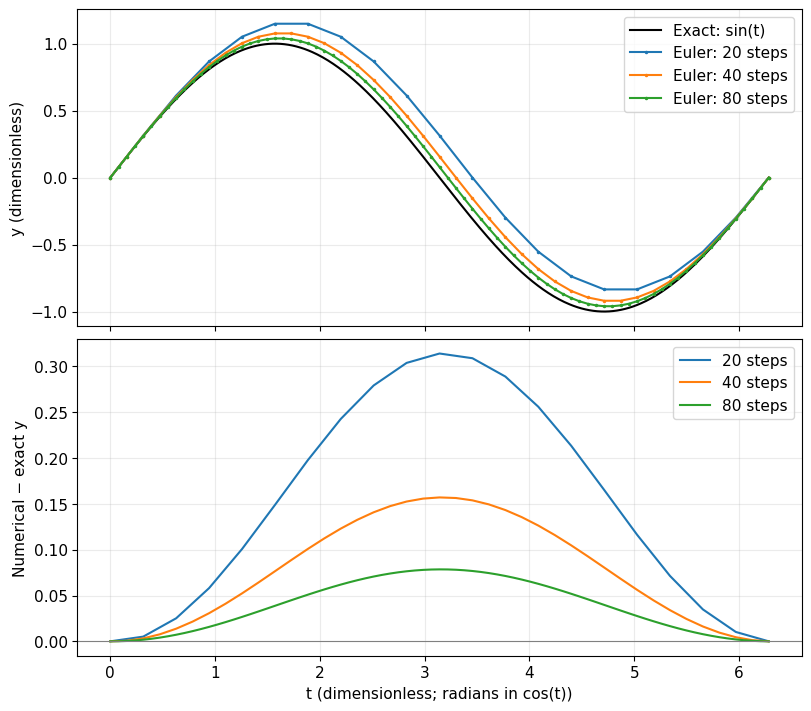

In [5]:
fig, axes = plt.subplots(2, 1, sharex=True, figsize=(8, 7), constrained_layout=True)
dense_time = np.linspace(0, 2 * np.pi, 500)
axes[0].plot(dense_time, np.sin(dense_time), color='black', label='Exact: sin(t)')
max_errors = []
for nsteps in [20, 40, 80]:
    time, y = euler_cosine(nsteps)
    error = y - np.sin(time)
    max_errors.append(np.max(np.abs(error)))
    axes[0].plot(time, y, '.-', label=f'Euler: {nsteps} steps', markersize=3)
    axes[1].plot(time, error, label=f'{nsteps} steps')
    print(f'{nsteps:3d} steps: dt = {time[1] - time[0]:.5f}, '
          f'max error = {max_errors[-1]:.6f}, final error = {abs(error[-1]):.3e}')
print('Successive maximum-error ratios:', np.array(max_errors[:-1]) / max_errors[1:])
axes[0].set_ylabel('y (dimensionless)')
axes[1].set(xlabel='t (dimensionless; radians in cos(t))', ylabel='Numerical − exact y')
axes[1].axhline(0, color='0.5', linewidth=0.8)
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend()
plt.show()


## 2. Same surface temperature, different greenhouse models

Consider the surface and one atmospheric layer model from class. The atmosphere transmits sunlight, absorbs a fraction ε of surface infrared radiation, and emits εσTₐ⁴ upward and downward. The surface emits σTₛ⁴. Albedo is prescribed, and convection and evaporation are omitted.

The full time-dependent energy budgets are

**Surface:**

$$
C_s\frac{dT_s}{dt}=Q+\epsilon\sigma T_a^4-\sigma T_s^4.
$$

**Atmosphere:**

$$
C_a\frac{dT_a}{dt}=\epsilon\sigma T_s^4-2\epsilon\sigma T_a^4.
$$

Absorbed sunlight is

$$
Q=\frac{S_0(1-\alpha)}{4}.
$$

Here Tₛ and Tₐ are surface and atmospheric temperatures, and Cₛ and Cₐ are their heat capacities per unit area, in J m⁻² K⁻¹. Each right-hand side is an incoming-minus-outgoing energy flux in W m⁻²; time is in seconds. The factor of two in the atmospheric budget accounts for emission upward and downward.

S₀ is incoming solar flux before averaging over the planet, α is planetary albedo, σ is the Stefan–Boltzmann constant, and ε is a dimensionless absorption parameter. All temperatures in radiation calculations must be in **kelvin**. The parameter ε is not a CO₂ concentration, but rather the net absorption effect due to all components of the atmosphere that absorb longwave radiation.

### 2a. Find the equilibrium temperatures

At equilibrium, neither temperature changes with time. Set both temperature tendencies to zero in the equations above and report expressions for the equilibrium surface temperature Tₛ and atmospheric temperature Tₐ in terms of S₀, α, ε, and σ. Show your algebra, starting with the atmospheric budget. Assume 0 < ε ≤ 1.


**Your response:**

At equilibrium nothing changes in time, so set both tendencies to zero:

Cs(dTs/dt) = 0, 
Ca(dTa/dt) = 0

Start with the atmosphere:

0 = ϵσTs^4 - 2ϵσT_a^4

Cancel ϵσ:
Ts^4 = 2Ta^4
so,
Ta = Ts/2^(1/4) 

For surface budget, 
0 = Q + ϵσTa^4 - σTs^4.

Substituting Ta^4 = Ts^4/2:

Q + ϵσ (Ts^4) / 2 = σTs^4.

Q = σTs^4 (1 - ϵ/2)

Ts = [Q/(σ (1 - ϵ/2) )] ^ (1/4),  

Q = (S0 (1 - α)) /4

Ts = [(S0 (1 - α)) / 4σ(1 - ϵ/2)] ^ (1/4),  

Ta = 1/2^(1/4)  [(S0 (1 - α)) / 4σ(1 - ϵ/2)] ^(1/4)

Numerical results:

ε = 0, Ts = (Q/σ)^{1/4} ≈ 254.6 K, the bare-planet value. Ta is undetermined (0 = 0)
ε = 1 → Ts = (2Q/σ)^{1/4} ≈ 302.7 K.

Both are within 0≤ϵ≤1. Since 1 − ε/2 < 1, the surface is always warmer than the bare-planet value. 


### 2b. Fit two models to the same temperature

Imagine two hypothetical planets have the same incoming sunlight and equilibrium surface temperature, but different albedos:

| Quantity | Planet A | Planet B |
|:--|--:|--:|
| S₀ (W m⁻²) | 1361 | 1361 |
| α | 0.25 | 0.35 |
| Tₛ (K) | 288 | 288 |

1. Guess which planet may require stronger atmospheric absorption. Explain why.
2. Use your equilibrium result from 2a to find an expression for ε in terms of Q and Tₛ.
3. Implement that expression below and calculate ε for both planets. Check whether each lies in its allowed range 0 ≤ ε ≤ 1.


**Your response:**

1. Planet B has a higher albedo, so it absorbs less sunlight. To still have the same surface temperature, it needs stronger atmospheric absorption. So Planet B should require larger ϵ.

2. From 2a, equilibrium gives σTs⁴(1 − ε/2) = Q. Then:

1-ϵ /2 = Q / (σTs^4 )

ϵ/2 = 1 - (Q/(σTs^4 ))

ϵ = 2 (1 - (Q/(σTs^4 )) 

Q/σTs⁴ is the ratio of absorbed sunlight to surface emission. The more the surface emits relative to what it absorbs, the larger ε must be.

In [6]:
S0 = 1361.0                  # W m^-2
sigma = 5.670374419e-8        # W m^-2 K^-4
Ts_target = 288.0            # K
albedos = np.array([0.25, 0.35])
planet_names = ['A', 'B']

def fit_absorption(alpha, Ts=Ts_target, sunlight=S0):
    """Return epsilon needed to match Ts at the supplied albedo."""
    Q = sunlight * (1 - alpha) / 4
    # TODO: return your rearranged expression for epsilon.
    return 2 * (1 - Q / (sigma * Ts**4))
    raise NotImplementedError('Calculate absorption from equilibrium balance')

epsilons = fit_absorption(albedos)
for name, alpha, epsilon in zip(planet_names, albedos, epsilons):
    print(f'Planet {name}: albedo = {alpha:.2f}, absorption = {epsilon:.5f}')


Planet A: albedo = 0.25, absorption = 0.69170
Planet B: albedo = 0.35, absorption = 0.86614


### 2c. How does energy move around this system in equilibrium?

Complete the flux calculations in `equilibrium_fluxes` and return a dictionary with the supplied names. 
> A **dictionary** stores key–value pairs: here, each key is a flux name and its value is the calculated flux. For example, `example = {'temperature': 288.0}` stores a value that you can retrieve with `example['temperature']`. See the [Python tutorial on dictionaries](https://docs.python.org/3/tutorial/datastructures.html#dictionaries) for a refresher.

Use the following keys, with each flux value in W m⁻²:

- `solar`: absorbed sunlight.
- `surface`: all infrared radiation emitted by the surface.
- `absorbed`: surface infrared absorbed by the atmosphere.
- `direct`: surface infrared that escapes directly to space.
- `air_up`, `air_down`: atmospheric emission in each direction.

The code below prints a table and evaluates three **budget residuals**. Each residual is incoming minus outgoing energy flux, in W m⁻²:

- **Rₛ:** the net energy flux into the surface.
- **Rₐ:** the net energy flux into the atmospheric layer.
- **N:** the net energy flux into the whole planet, also called the **planetary energy imbalance**.

A positive residual means that the corresponding part of the system is gaining energy; a negative residual means it is losing energy. **OLR** stands for **outgoing longwave radiation**: the total infrared energy escaping to space per unit area per second. It includes radiation escaping directly from the surface and upward radiation from the atmosphere.

$$
R_s=Q+\text{air\_down}-\text{surface},
$$

$$
R_a=\text{absorbed}-\text{air\_up}-\text{air\_down},
$$

$$
N=Q-\mathrm{OLR},\qquad\mathrm{OLR}=\text{direct}+\text{air\_up}.
$$

At equilibrium all three residuals should be zero, apart from rounding error. If they are not, revisit the flux definitions.


In [7]:
def equilibrium_fluxes(alpha, epsilon, Ts=Ts_target):
    """Return equilibrium radiation fluxes, all in W m^-2 (epsilon > 0)."""
    Ta = Ts / 2**0.25
    Q = S0 * (1 - alpha) / 4
    surface = sigma * Ts**4
    absorbed = epsilon * surface
    direct = (1 - epsilon) * surface
    air_up = epsilon * sigma * Ta**4
    air_down = air_up

    return {
        'solar': Q,
        'surface': surface,
        'absorbed': absorbed,
        'direct': direct,
        'air_up': air_up,
        'air_down': air_down,
    }
   
    raise NotImplementedError('Calculate the radiation fluxes')


In [8]:
fluxes = [equilibrium_fluxes(a, e) for a, e in zip(albedos, epsilons)]
print(f'{"Flux (W m^-2)":24s} {"Planet A":>12s} {"Planet B":>12s}')
for key in ['solar', 'surface', 'absorbed', 'direct', 'air_up', 'air_down']:
    print(f'{key:24s} {fluxes[0][key]:12.3f} {fluxes[1][key]:12.3f}')
for name, f in zip(planet_names, fluxes):
    olr = f['direct'] + f['air_up']
    rs = f['solar'] + f['air_down'] - f['surface']
    ra = f['absorbed'] - f['air_up'] - f['air_down']
    imbalance = f['solar'] - olr
    print(f'Planet {name}: OLR = {olr:.3f} W m^-2; '
          f'residuals Rs = {rs:.2e}, Ra = {ra:.2e}, N = {imbalance:.2e} W m^-2')


Flux (W m^-2)                Planet A     Planet B
solar                         255.188      221.162
surface                       390.105      390.105
absorbed                      269.835      337.885
direct                        120.270       52.220
air_up                        134.918      168.943
air_down                      134.918      168.943
Planet A: OLR = 255.188 W m^-2; residuals Rs = 5.68e-14, Ra = -5.68e-14, N = 0.00e+00 W m^-2
Planet B: OLR = 221.162 W m^-2; residuals Rs = 0.00e+00, Ra = 0.00e+00, N = 0.00e+00 W m^-2


### 2d. What did fitting the temperature establish?

1. Which fluxes differ between the two planets even though their surface temperatures match? Use two numbers from your table.
2. Explain why surface emission can exceed absorbed sunlight without violating energy conservation. Which transfers cancel when you add the surface and atmospheric budgets?
3. If these were competing models of one planet, what independent observation could distinguish them? Why would matching the temperature used for calibration not provide an independent test?


**Your response:**

1. Even though the surface temperatures match, these fluxes differ:

absorbed sunlight, surface IR absorbed by the atmosphere, direct surface IR escape, atmospheric upward/downward emission.
For Example numbers: Planet A solar flux is 255.19 Wm^−2 , while Planet B is 221.16 Wm^−2.

2. 	Surface emission can exceed absorbed sunlight because the surface also receives downward infrared radiation from the atmosphere. The surface budget is

Q + air_down = surface emission.

When you add the surface and atmosphere budgets, the internal transfers cancel. The downward atmospheric emission cancels, and the part of surface emission absorbed by the atmosphere cancels with the atmospheric absorption term. What remains is  N = Q - OLR.

3. An independent observation could be, for example, measured OLR, atmospheric temperature, or downward longwave radiation at the surface. Matching the calibration temperature is not an independent test because ϵ was chosen specifically to make that temperature match. 


### 2e. Compensate for weaker sunlight

For a third hypothetical planet, set α = 0.30 and fit ε to 288 K. Then reduce S₀ by 5%, keeping α and ε fixed.

1. Guess whether the planetary energy imbalance immediately after the change will be positive or negative, then calculate its value before temperatures change.
2. Calculate the new equilibrium surface temperature.
3. With the weaker sunlight and the original ε, find the albedo that would restore 288 K.

You may use algebra, Python, or a combination; show your method and report the results with units in the response cell. A code cell is provided below if you need it.

Keep the original `S0` unchanged and use a separate variable, such as `S_weaker = 0.95 * S0`, for the reduced sunlight. Fit ε using the original sunlight, then keep that fitted value fixed. Calculate the absorbed sunlight directly for each state using the appropriate solar flux; `equilibrium_fluxes` uses the original `S0` and does not take a sunlight argument.


In [9]:
# Optional: use this cell for your calculations for 2e.
# Keep S0 unchanged; use a separate variable for the reduced sunlight.


**Your response:**


For α = 0.30and S_0 = 1361:
Q_orig =1361(1-0.30) / 4 = 238.175 Wm^(-2).

Fit ϵ: ϵ = 2(1-238.175/(σ(288)^4 )) ≈ 0.7789.

Now dropping sunlight by 5%:

S_weaker = 0.95S_0 = 1292.95 Wm^(-2),
Q_weaker = (S_weaker  (1-0.30))/4 = 226.266  Wm^(-2)

1. 	Immediately after the sunlight reduction, temperatures have not changed, so OLR is still approximately the old equilibrium value 238.175 W m^(-2). The planetary imbalance is
   
N = Q_weaker - OLR = 226.266 - 238.175 ≈ -11.91 Wm^(-2).

Negative means the planet is losing energy and will cool.

2. So the planet initially loses energy. The imbalance is negative. New equilibrium surface temperature with same ϵ: T_(s,new ) = 288 (0.95) ^ (1/4) ≈ 284.33 K.

So it cools by about 3.67" " K.

3. 	To restore 288 K with the weaker sunlight, need the same absorbed solar flux Q_orig = 238.175 Wm^(-2). Thus
238.175 = 1292.95 (1-α_new)/4.

1-α_new = 4(238.175) / 1292.95 = 0.7368,

α_new ≈  0.2632.

A lower albedo is needed to compensate for weaker sunlight.
 



## 3. How much warming, how quickly, and how much stored energy?

Now let's consider the linear energy balance model from week 3:

$$
C\frac{dT'}{dt}=F-\lambda T'.
$$

- T′: temperature change relative to an initial equilibrium, in K.
- F: constant imposed forcing after t = 0, in W m⁻².
- λ > 0: radiative restoring strength, in W m⁻² K⁻¹.
- C: heat capacity per unit area, in J m⁻² K⁻¹.

All experiments start from T′(0) = 0. Time must be in **seconds** when using these coefficients.

For comparison, the exact solution is

$$
T'(t)=\frac{F}{\lambda}\left(1-e^{-t/\tau}\right),\qquad\tau=\frac{C}{\lambda}.
$$

Here **τ (tau)** is the **adjustment time**, which describes how quickly the temperature approaches its new equilibrium. For this solution, after one τ about 63% of the eventual warming has occurred. It is not the time required to reach equilibrium fully; the remaining difference continues to shrink. With the units used here, C/λ gives τ in seconds.

**Equilibrium warming** is the eventual temperature increase relative to the starting equilibrium when the forcing is maintained. It is the long-time limit of T′, equal to F/λ in this model. This is a temperature change, not the absolute surface temperature.

### 3a. Use Euler’s method to calculate temperature over time

Adapt your loop from Part 1 to calculate the temperature change step by step using the equation above. At each step, your code should:

1. Use the **current** temperature change to calculate its rate of change from the energy-balance equation.
2. Multiply that rate by the time-step length to find how much the temperature changes during the step.
3. Add that amount to the current value and save the result as the next value.

First write the equation for this update in the response cell, then complete the function below. Start from zero temperature change. Keep `time` and the time-step length in seconds inside the function; the plotting code converts time to years.


**Your response:**

Step 0.10 years: maximum error = 0.023576 K
Step 0.05 years: maximum error = 0.011694 K

In [10]:
YEAR = 365.0 * 86400.0       # seconds in the fixed-length year used here
F_ref = 4.0                 # W m^-2
lambda_ref = 1.2            # W m^-2 K^-1; positive means restoring
C_ref = 1.0e8               # J m^-2 K^-1

def exact_warming(time_seconds, F, restoring, C):
    """Analytical warming (K), starting from zero, under a constant forcing."""
    return (F / restoring) * (1 - np.exp(-np.asarray(time_seconds) * restoring / C))

def euler_climate(F, restoring, C, years=50.0, dt_years=0.1):
    """Return time (seconds) and warming (K), starting from zero."""
    nsteps = int(np.ceil(years / dt_years))
    time = np.linspace(0.0, years * YEAR, nsteps + 1)
    dt = time[1] - time[0]
    warming = np.zeros(len(time))
    warming[0] = 0.0
    for n in range(nsteps):
        dTdt = (F - restoring * warming[n]) / C
        warming[n + 1] = warming[n] + dt * dTdt

    return time, warming


Run the comparison below for steps of 0.1 and 0.05 years. Report each maximum error relative to the exact solution. Does reducing the step improve agreement? 

Step 0.10 years: maximum error = 0.023576 K
Step 0.05 years: maximum error = 0.011694 K


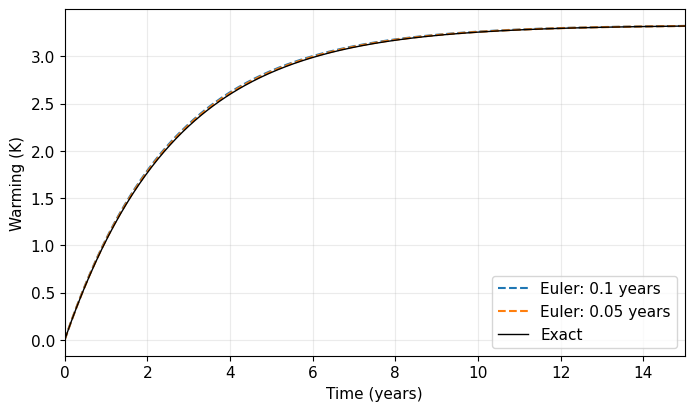

In [11]:
fig, ax = plt.subplots()
for step in [0.1, 0.05]:
    time, warming = euler_climate(F_ref, lambda_ref, C_ref, dt_years=step)
    exact = exact_warming(time, F_ref, lambda_ref, C_ref)
    print(f'Step {step:.2f} years: maximum error = {np.max(np.abs(warming - exact)):.6f} K')
    ax.plot(time / YEAR, warming, label=f'Euler: {step} years', linestyle='--')
ax.plot(time / YEAR, exact, color='black', label='Exact', linewidth=1)
ax.set(xlim=(0, 15), xlabel='Time (years)', ylabel='Warming (K)')
ax.grid(alpha=0.25)
ax.legend()
plt.show()


**Your response:**

_Write here._


### 3b. Same forcing and restoring, different heat capacities

Compare the reference model with a model having **four times the heat capacity**. Keep F and λ fixed.

Before calculating, guess the effect on (i) initial warming rate (the rate of temperature increase at t = 0, immediately after the forcing begins), (ii) equilibrium warming, and (iii) adjustment time. Use the linearized energy budget and its analytical solution to explain your reasoning.


**Your response:**

(i)   Initial warming rate: dT'/dt = F/C at t=0. Larger C means smaller initial rate.
(ii)  Equilibrium warming: F/λ, independent of C.
(iii) Adjustment time: τ = C/λ. Larger C means larger τ.
 

Complete `response_properties` using the equation and exact solution above. Return the initial warming rate in K/year, equilibrium warming in K, and adjustment time in years. At t = 0, T′ = 0.

The printed results and plot will help check your guesses. We use the exact solution for the remaining experiments so changes in numerical error do not obscure the physical comparisons.


In [12]:
def response_properties(F, restoring, C):
    """Return (initial rate in K/year, equilibrium warming in K, tau in years)."""
    # TODO: calculate and return all three quantities, converting time units.
    initial_rate = (F / C) * YEAR      # K/year
    equilibrium = F / restoring         # K
    tau = (C / restoring) / YEAR        # years
    return initial_rate, equilibrium, tau
    
cases = {
    'Reference': (F_ref, lambda_ref, C_ref),
    '4 × heat capacity': (F_ref, lambda_ref, 4 * C_ref),
}
for label, params in cases.items():
    rate, equilibrium, tau = response_properties(*params)
    print(f'{label}: initial rate = {rate:.4f} K/year, '
          f'equilibrium = {equilibrium:.4f} K, tau = {tau:.4f} years')


Reference: initial rate = 1.2614 K/year, equilibrium = 3.3333 K, tau = 2.6425 years
4 × heat capacity: initial rate = 0.3154 K/year, equilibrium = 3.3333 K, tau = 10.5699 years


### 3c. Less warming, but more stored energy?

Continue comparing the **two linear energy-balance models from 3b**:

- **Reference model:** uses the original heat capacity, `C_ref`.
- **Larger-heat-capacity model:** uses four times that heat capacity, `4 * C_ref`.

Both have the same constant forcing F and restoring strength λ, and both start from T′ = 0. Only their heat capacities differ. Compare them **10 years after the forcing begins**.

The planetary energy imbalance, in W m⁻², is

$$
N=F-\lambda T'.
$$

The increase in stored energy per unit area, in J m⁻², is

$$
E'=CT'.
$$

The stored-energy change is zero at t = 0.

1. Before calculating, guess which model has a larger increase in stored energy by year 10. Explain your reasoning.
2. Calculate T′, N, and E′ at year 10 for both models. Complete the function below; the code prints the comparison.
3. Which has warmed more? Which has a larger increase in stored energy? Explain why those rankings can differ.
4. Explain the difference between an energy imbalance and an increase in stored energy, including their units. What does N = 0 imply about the **rate** of energy storage?


**Your response:**

1. Guess is that the 4C model stores more energy by year 10, even though it warms less. The stored energy is E'= CT'. The larger heat capacity can outweigh the smaller temperature change.
2. done
3. The reference model warmed more (3.26 K vs 2.04 K), but the 4C model stored more energy (8.16×10^8 vs 3.26×10^8  Jm^(-2)). The rankings differ because stored energy is the product of heat capacity and temperature change. A larger heat capacity can store more energy at a lower temperature.

4. The imbalance N(units Wm^(-2)) is the rate at which the system gains energy. The stored energy E'(units Jm^(-2)) is the accumulated energy. If N = 0, the system is not gaining or losing net energy, so the rate of energy storage is zero — the temperature stops changing.


In [13]:
def state_at_year(year, F, restoring, C):
    """Return warming (K), imbalance (W m^-2), stored energy change (J m^-2)."""
    warming = exact_warming(year * YEAR, F, restoring, C)
    imbalance = F - restoring * warming
    stored_energy = C * warming
    return warming, imbalance, stored_energy


print(f'{"Model":22s} {"Warming (K)":>14s} {"N (W m^-2)":>14s} {"E\' (J m^-2)":>16s}')
for label, params in cases.items():
    warming, imbalance, energy = state_at_year(10, *params)
    print(f'{label:22s} {warming:14.4f} {imbalance:14.4f} {energy:16.4e}')

Model                     Warming (K)     N (W m^-2)      E' (J m^-2)
Reference                      3.2576         0.0909       3.2576e+08
4 × heat capacity              2.0391         1.5530       8.1565e+08


### 3d. Change restoring strength instead

Double λ in the reference model, keeping F and C fixed.

Guess how the initial warming rate, equilibrium warming, and adjustment time will change, then calculate their values. Use `response_properties` and `exact_warming` to compare this case with the reference. Add a plot with labeled curves.

Explain how this experiment differs from increasing heat capacity. In which experiment does the model have a smaller equilibrium response to the same forcing?


Reference: initial rate = 1.2614 K/year, equilibrium = 3.3333 K, tau = 2.6425 years
2 x lambda: initial rate = 1.2614 K/year, equilibrium = 1.6667 K, tau = 1.3212 years


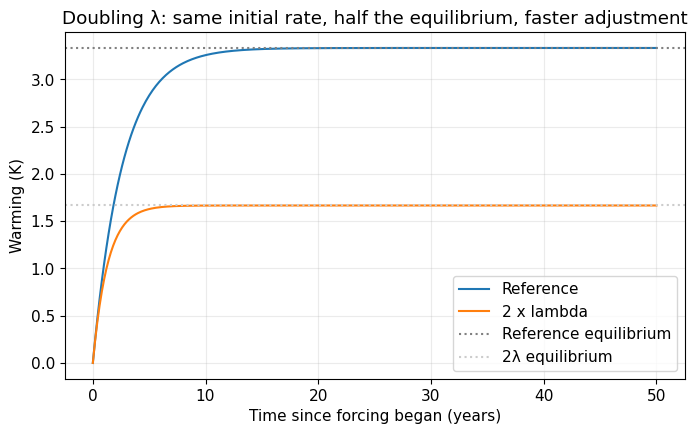

In [14]:
# 3d: double lambda in the reference model, keep F and C fixed.
lambda_double = 2 * lambda_ref

cases_3d = {
    'Reference': (F_ref, lambda_ref, C_ref),
    '2 x lambda': (F_ref, lambda_double, C_ref),
}

# Compare the three response properties.
for label, params in cases_3d.items():
    rate, equilibrium, tau = response_properties(*params)
    print(f'{label}: initial rate = {rate:.4f} K/year, '
          f'equilibrium = {equilibrium:.4f} K, tau = {tau:.4f} years')

# Plot the temperature curves using the exact solution.
time_years = np.linspace(0, 50, 501)
time_seconds = time_years * YEAR

fig, ax = plt.subplots(figsize=(8, 4.5))
for label, params in cases_3d.items():
    F, lam, C = params
    ax.plot(time_years, exact_warming(time_seconds, F, lam, C), label=label)

# Mark the two equilibrium levels.
ax.axhline(F_ref / lambda_ref, color='0.5', linestyle=':',
           label='Reference equilibrium')
ax.axhline(F_ref / lambda_double, color='0.8', linestyle=':',
           label='2λ equilibrium')

ax.set(xlabel='Time since forcing began (years)', ylabel='Warming (K)',
       title='Doubling λ: same initial rate, half the equilibrium, faster adjustment')
ax.grid(alpha=0.25)
ax.legend()
plt.show()

**Your response:**

Guesses:

    initial warming rate: unchanged, because at t=0, dT'/dt=F/C
	equilibrium warming: halved, because T_eq' = F/λ
	adjustment time: halved, because τ = C/λ
 
**Interpretation for your written response**:

The initial warming rate is unchanged because at t=0, T'=0, so dT'/dt = F/C. Doubling λ does not affect F/C.
The equilibrium warming is halved because T_eq'= F/λ.
The adjustment time is halved because τ = C/λ.
In the plot, the 2λ curve rises at the same initial slope but flattens out sooner and at a lower level. This differs from increasing heat capacity, which slows the approach to the same equilibrium.
 



### 3e. Can a temperature curve tell us everything?

Double **all three** coefficients F, λ, and C in the reference model.

1. Use the formulas to work out how the temperature curve changes. Check by plotting both curves.
2. Could even a perfectly known temperature curve determine these three coefficients separately? Which combinations of coefficients appear in the exact solution?
3. Would an independent estimate of forcing help distinguish the two cases? Explain.

This question concerns the information available from temperature alone; it does not require a fitting algorithm.


Model            Init rate (K/yr)    Equil (K)   tau (yr)
Reference                  1.2614       3.3333     2.6425
2F, 2λ, 2C                 1.2614       3.3333     2.6425


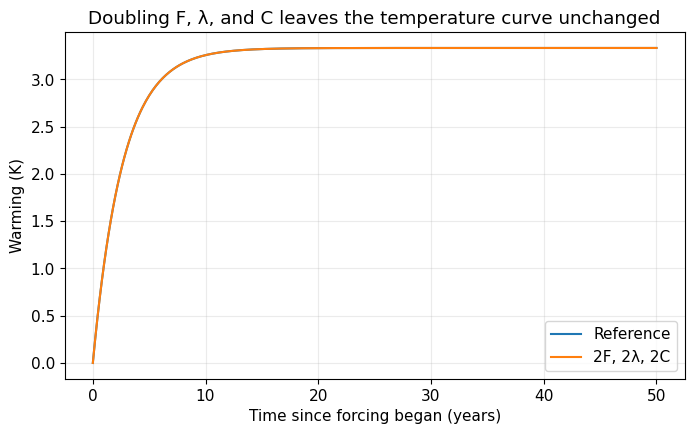

Maximum difference between the two curves: 0.000e+00 K


In [15]:
# 3e: double all three coefficients in the reference model.
F_double = 2 * F_ref
lambda_double = 2 * lambda_ref
C_double = 2 * C_ref

cases_3e = {
    'Reference': (F_ref, lambda_ref, C_ref),
    '2F, 2λ, 2C': (F_double, lambda_double, C_double),
}

# 1. Compare the three response properties.
print(f'{"Model":14s} {"Init rate (K/yr)":>18s} {"Equil (K)":>12s} {"tau (yr)":>10s}')
for label, params in cases_3e.items():
    rate, eq, tau = response_properties(*params)
    print(f'{label:14s} {rate:18.4f} {eq:12.4f} {tau:10.4f}')

# Plot both exact temperature curves.
time_years = np.linspace(0, 50, 501)
time_seconds = time_years * YEAR

fig, ax = plt.subplots(figsize=(8, 4.5))
for label, params in cases_3e.items():
    F, lam, C = params
    ax.plot(time_years, exact_warming(time_seconds, F, lam, C), label=label)

ax.set(xlabel='Time since forcing began (years)', ylabel='Warming (K)',
       title='Doubling F, λ, and C leaves the temperature curve unchanged')
ax.grid(alpha=0.25)
ax.legend()
plt.show()

# Optional numerical check that the two curves are identical.
t = np.linspace(0, 50, 501) * YEAR
diff = exact_warming(t, F_ref, lambda_ref, C_ref) - \
       exact_warming(t, F_double, lambda_double, C_double)
print(f'Maximum difference between the two curves: {np.max(np.abs(diff)):.3e} K')

**Your response:**

1. Both rows give the same initial rate (1.2614" " K/yr), the same equilibrium (3.3333" " K), and the same τ(2.642" " yr. The two curves lie exactly on top of each other. The maximum difference is essentially 0" " K(floating-point roundoff).

2. No. The exact solution depends on the coefficients only through the two combinations
   F/λ  "and"   C/λ.

Only these two ratios appear. Any two triples (F,λ,C) that give the same ratios produce exactly the same T'(t). So temperature alone cannot separate the three coefficients (the problem is underdetermined).

3.  Yes. If we measure F independently (for example, from observed radiative forcing), then can combine it with the two ratios: λ = F/(T_eq'), C = λτ.

Once F is known, λ and C follow from the equilibrium warming and the adjustment time, so the three coefficients can be distinguished. Without an independent F, the pair (2F, 2λ, 2C) is indistinguishable from the reference (F, λ, C) using temperature alone.
 

## Before submitting

- Complete the required code and written responses, including your initial guesses and interpretations.
- Restart the kernel and run all cells in order. Check that your results do not depend on variables left over from earlier work.
- Save the notebook with plots, numerical output, and units visible.


In [44]:
cd path/to/your/notebook/folder
ls

UsageError: Line magic function `%` not found.
